# Spatial Proximity Graphs

This notebook generates and visualises spatial graphs built from proximity: k-nearest-neighbour, Delaunay, Gilbert, and Waxman graphs over points of interest in Tokyo, followed by multi-layer bridging, contiguity graphs of London wards, and polygon-to-point grouping.

## Overview

Proximity graphs encode the assumption that near things interact. Different constructions apply that assumption differently — fixed neighbour counts, triangulations, hard distance thresholds, probabilistic decay — and each produces a different network from the same points. city2graph returns every variant as GeoDataFrames or NetworkX graphs and supports Euclidean, Manhattan, and network distances throughout.

## 1. Setup and Environment

In [1]:
import warnings

import geopandas as gpd
import contextily as ctx
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
from IPython.display import HTML
from matplotlib import animation

import city2graph as c2g

warnings.filterwarnings("ignore")

## 2. Retrieve Points of Interest

Restaurant POIs around Shibuya, Tokyo are fetched with OSMnx and filtered to point geometries. The street network is fetched as well, for computing network distances later.

In [2]:
poi_tags = {
    "amenity": ["restaurant"]
    }

#poi_gdf = ox.features_from_place("Shibuya, Tokyo, Japan", poi_tags)
poi_gdf = ox.features_from_point(
    (35.658514, 139.70133),  # Tokyo Tower coordinates
    tags=poi_tags,
    dist=1000,  # Search radius in meters
    )

# Filter to include only nodes, not ways and relations
poi_gdf = poi_gdf[poi_gdf.index.get_level_values("element") == "node"]

# Reproject to a projected CRS for accurate centroids
poi_gdf = poi_gdf.to_crs(epsg=6677)

In [3]:
segments_G = ox.graph_from_point(
    (35.658514, 139.70133),  # Tokyo Tower coordinates
    dist=1000,  # Search radius in meters
    )

segments_gdf = c2g.nx_to_gdf(segments_G, nodes=False, edges=True)

In [4]:
import matplotlib.colors as mcolors

def get_degree_colors(graph, cmap_name='plasma'):
    """Generate colors based on node degree."""
    if not graph:
        return []
    
    degree_dict = dict(graph.degree())
    values = list(degree_dict.values())
    
    if not values:
        return []
        
    norm = mcolors.Normalize(vmin=min(values), vmax=max(values))
    cmap = plt.get_cmap(cmap_name)
    
    # Match order of nodes in graph
    return [mcolors.to_hex(cmap(norm(degree_dict[n]))) for n in graph.nodes()]

## 3. K-Nearest Neighbors (KNN) Graph

`knn_graph` connects each point to its $k$ nearest neighbours. The distance metric can be `"manhattan"`, `"euclidean"`, or `"network"`; network distance requires the streets GeoDataFrame. The panels below compare the three metrics, and the video shows how the graph densifies as $k$ grows.

In [5]:
knn_l1_nodes, knn_l1_edges = c2g.knn_graph(
    poi_gdf,
    distance_metric="manhattan",
    network_gdf=segments_gdf.to_crs(epsg=6677)
    )

knn_l2_nodes, knn_l2_edges = c2g.knn_graph(
    poi_gdf,
    distance_metric="euclidean",
    network_gdf=segments_gdf.to_crs(epsg=6677)
    )

knn_net_nodes, knn_net_edges = c2g.knn_graph(
    poi_gdf,
    k=10,
    distance_metric="network",
    network_gdf=segments_gdf.to_crs(epsg=6677)
    )

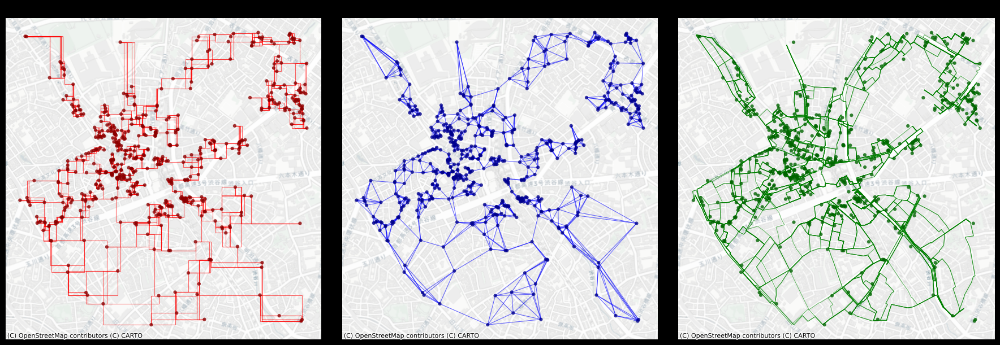

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot Manhattan distance KNN Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=knn_l1_edges,
    ax=axes[0],
    node_color='darkred',
    edge_color='red',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6
    )

ctx.add_basemap(axes[0], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)
axes[0].set_title('KNN Graph - Manhattan Distance', fontsize=12, fontweight='bold')
axes[0].set_axis_off()

# Plot Euclidean distance KNN Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=knn_l2_edges,
    ax=axes[1],
    node_color='darkblue', 
    edge_color='blue',
    markersize=20, 
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6
    )

ctx.add_basemap(axes[1], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)
axes[1].set_title('KNN Graph - Euclidean Distance', fontsize=12, fontweight='bold')
axes[1].set_axis_off()

# Plot Network distance KNN Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=knn_net_edges,
    ax=axes[2],
    node_color='darkgreen',
    edge_color='green',
    markersize=20, 
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6
    )

ctx.add_basemap(axes[2], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)
axes[2].set_title('KNN Graph - Network Distance', fontsize=12, fontweight='bold')
axes[2].set_axis_off()

plt.tight_layout()
plt.show()

The output can also be obtained as an `nx.Graph` object.

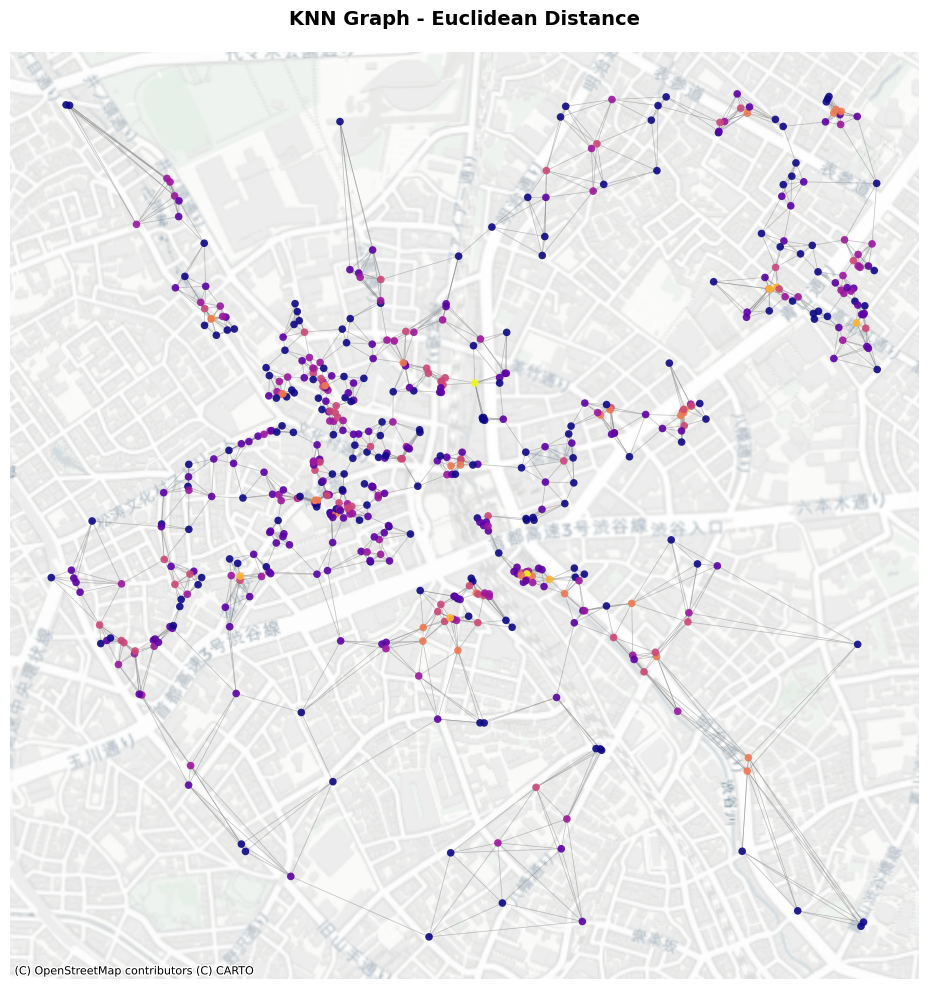

In [7]:
knn_l2_G = c2g.knn_graph(
    poi_gdf,
    distance_metric="euclidean",
    as_nx=True
)

fig, ax = plt.subplots(figsize=(12, 10))

c2g.plot_graph(
    graph=knn_l2_G,
    ax=ax,
    node_color=get_degree_colors(knn_l2_G),
    edge_color="grey",
    edge_alpha=0.5,
    edge_linewidth=0.5,
    node_alpha=0.9,
    markersize=30,
    bgcolor="white"
    )

if poi_gdf.crs:
    ctx.add_basemap(ax, crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

ax.set_title("KNN Graph - Euclidean Distance", fontsize=14, fontweight="bold", pad=20)
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [8]:
HTML("""
<video controls style="width: 100%; max-width: 800px; height: auto;">
    <source src="../assets/videos/knn_graph.mp4" type="video/mp4">
</video>
""")

## 4. Delaunay Graph

The Delaunay triangulation connects points whose Voronoi cells touch, giving a planar graph that spans the whole point set.

In [9]:
del_l1_nodes, del_l1_edges = c2g.delaunay_graph(
    poi_gdf,
    distance_metric="manhattan"
    )

del_l2_nodes, del_l2_edges = c2g.delaunay_graph(
    poi_gdf,
    distance_metric="euclidean"
    )

del_net_nodes, del_net_edges = c2g.delaunay_graph(
    poi_gdf,
    distance_metric="network",
    network_gdf=segments_gdf.to_crs(epsg=6677)
    )

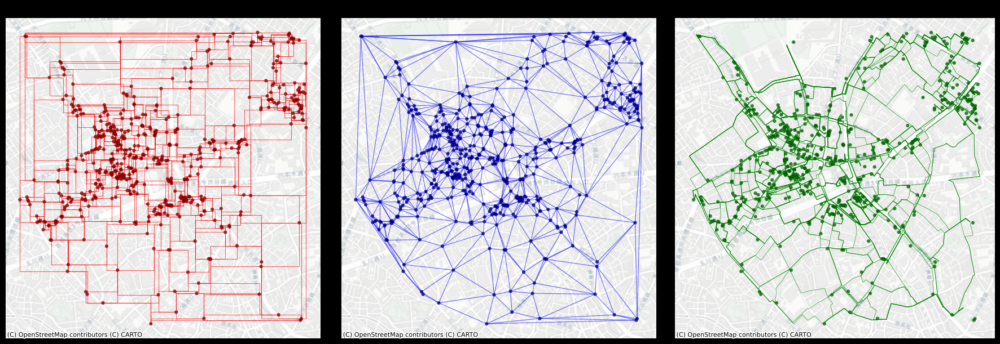

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot Manhattan distance Delaunay Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=del_l1_edges,
    ax=axes[0],
    node_color='darkred',
    edge_color='red',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6
    )

ctx.add_basemap(axes[0], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)
axes[0].set_title(
    'Delaunay Graph - Manhattan Distance', 
    fontsize=12, 
    fontweight='bold'
    )
axes[0].set_axis_off()

# Plot Euclidean distance Delaunay Graph
c2g.plot_graph(nodes=poi_gdf,
               edges=del_l2_edges,
               ax=axes[1],
               node_color='darkblue',
               edge_color='blue',
               markersize=20,
               node_alpha=0.8,
               edge_linewidth=0.8,
               edge_alpha=0.6
               )

ctx.add_basemap(axes[1], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)
axes[1].set_title(
    'Delaunay Graph - Euclidean Distance',
    fontsize=12, 
    fontweight='bold'
    )
axes[1].set_axis_off()

# Plot Network distance Delaunay Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=del_net_edges,
    ax=axes[2],
    node_color='darkgreen',
    edge_color='green',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6
    )

ctx.add_basemap(axes[2], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)
axes[2].set_title(
    'Delaunay Graph - Network Distance', 
    fontsize=12, 
    fontweight='bold'
    )
axes[2].set_axis_off()

plt.tight_layout()
plt.show()

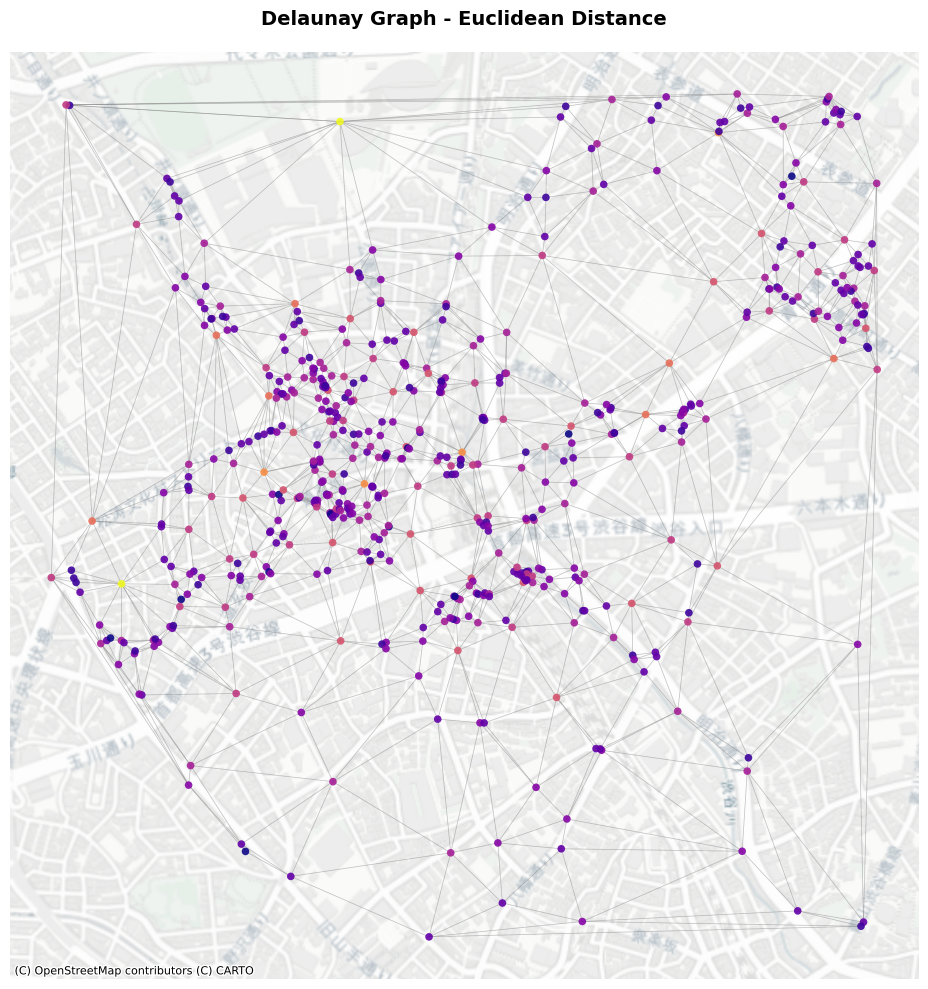

In [11]:
del_l2_G = c2g.delaunay_graph(
    poi_gdf,
    distance_metric="euclidean",
    as_nx=True
    )

fig, ax = plt.subplots(figsize=(12, 10))

c2g.plot_graph(
    graph=del_l2_G,
    ax=ax,
    node_color=get_degree_colors(del_l2_G),
    edge_color="grey",
    edge_alpha=0.5,
    edge_linewidth=0.5,
    node_alpha=0.9,
    markersize=30,
    bgcolor="white"
    )

if poi_gdf.crs:
    ctx.add_basemap(ax, crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

ax.set_title(
    "Delaunay Graph - Euclidean Distance", 
    fontsize=14,
    fontweight="bold",
    pad=20
    )

ax.set_axis_off()
plt.tight_layout()
plt.show()

## 5. Fixed Radius Graph (Gilbert Graph)

`fixed_radius_graph` connects every pair of points within a radius $r$ of each other — the deterministic counterpart of the Gilbert random graph, in which the points themselves are placed at random. The video shows the effect of increasing $r$.

In [12]:
fix_l1_nodes, fix_l1_edges = c2g.fixed_radius_graph(
    poi_gdf,
    distance_metric="manhattan",
    radius=100
    )

fix_l2_nodes, fix_l2_edges = c2g.fixed_radius_graph(
    poi_gdf,
    distance_metric="euclidean",
    radius=100
    )

fix_net_nodes, fix_net_edges = c2g.fixed_radius_graph(
    poi_gdf,
    distance_metric="network",
    radius=100,
    network_gdf=segments_gdf.to_crs(epsg=6677)
    )

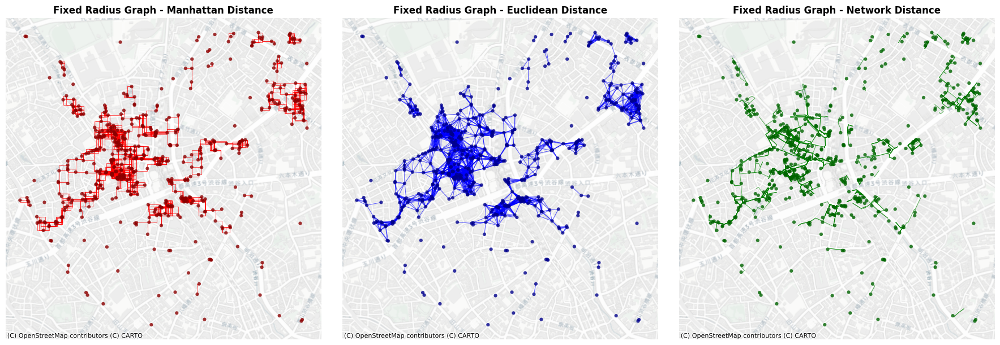

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot Manhattan distance Fixed Radius Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=fix_l1_edges,
    ax=axes[0],
    node_color='darkred',
    edge_color='red',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6,
    bgcolor="white"
    )

ctx.add_basemap(axes[0], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

axes[0].set_title(
    'Fixed Radius Graph - Manhattan Distance',
    fontsize=12,
    fontweight='bold'
    )
axes[0].set_axis_off()

# Plot Euclidean distance Fixed Radius Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=fix_l2_edges,
    ax=axes[1],
    node_color='darkblue',
    edge_color='blue',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6,
    bgcolor="white"
    )

ctx.add_basemap(axes[1], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

axes[1].set_title(
    'Fixed Radius Graph - Euclidean Distance',
    fontsize=12,
    fontweight='bold'
    )
axes[1].set_axis_off()

# Plot Network distance Fixed Radius Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=fix_net_edges,
    ax=axes[2],
    node_color='darkgreen',
    edge_color='green',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6,
    bgcolor="white"
    )

ctx.add_basemap(axes[2], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

axes[2].set_title(
    'Fixed Radius Graph - Network Distance',
    fontsize=12,
    fontweight='bold'
    )
axes[2].set_axis_off()

plt.tight_layout()
plt.show()

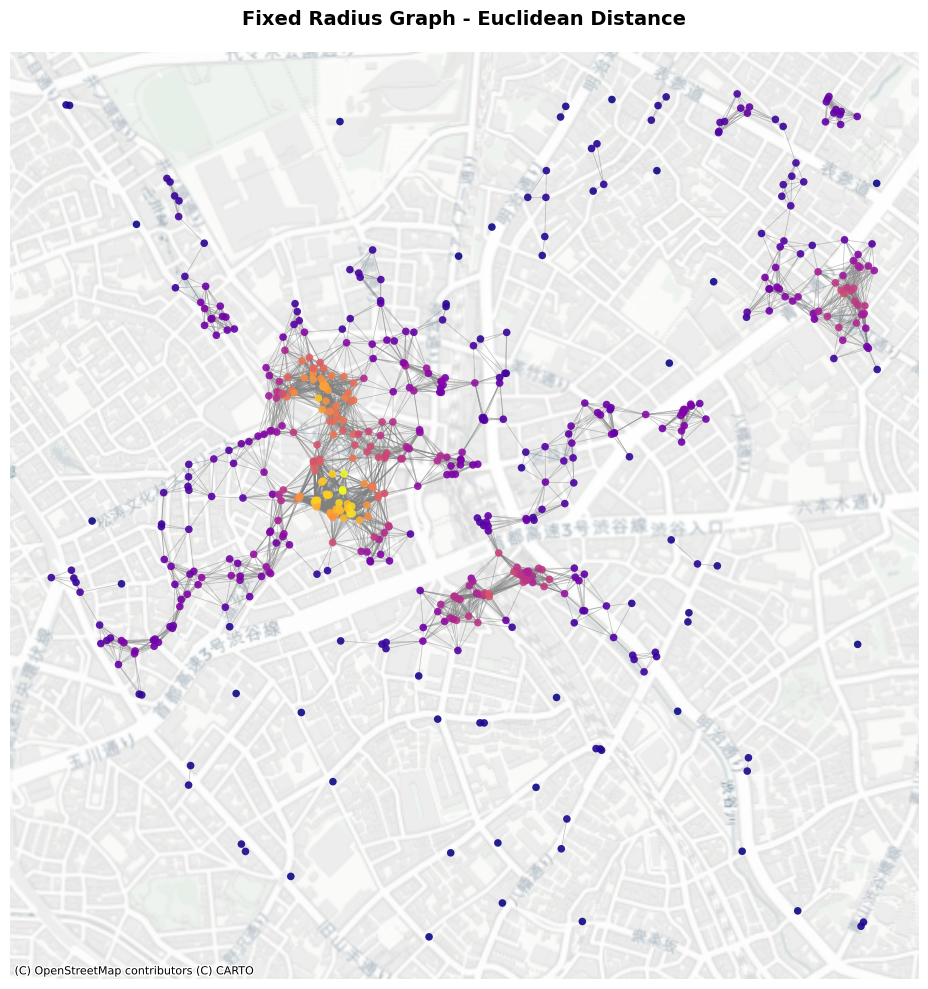

In [14]:
gil_l2_G = c2g.fixed_radius_graph(
    poi_gdf,
    distance_metric="euclidean",
    radius=100,
    as_nx=True
    )

fig, ax = plt.subplots(figsize=(12, 10))

c2g.plot_graph(
    graph=gil_l2_G,
    ax=ax,
    node_color=get_degree_colors(gil_l2_G),
    edge_color="grey",
    edge_alpha=0.5,
    edge_linewidth=0.5,
    node_alpha=0.9,
    markersize=30,
    bgcolor="white"
    )

if poi_gdf.crs:
    ctx.add_basemap(ax, crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

ax.set_title(
    "Fixed Radius Graph - Euclidean Distance",
    fontsize=14,
    fontweight="bold",
    pad=20
    )
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [15]:
HTML("""
<video controls style="width: 100%; max-width: 800px; height: auto;">
    <source src="../assets/videos/gilbert_graph.mp4" type="video/mp4">
</video>
""")

## 6. Waxman Graph (Soft Random Geometric Model)

The Waxman graph connects nodes probabilistically, with the probability decaying over distance:

$$H_{ij} = \beta e^{-\frac{d_{ij}}{r_0}}$$

where $d_{ij}$ is the Euclidean distance between nodes $i$ and $j$, $r_0$ sets the distance scale, and $\beta$ scales the overall connection probability.

In [16]:
wax_l1_nodes, wax_l1_edges = c2g.waxman_graph(
    poi_gdf,
    distance_metric="manhattan",
    r0=100,
    beta=0.5
    )
    
wax_l2_nodes, wax_l2_edges = c2g.waxman_graph(
    poi_gdf,
    distance_metric="euclidean",
    r0=100,
    beta=0.5
    )

wax_net_nodes, wax_net_edges = c2g.waxman_graph(
    poi_gdf,
    distance_metric="network",
    r0=100,
    beta=0.5,
    network_gdf=segments_gdf.to_crs(epsg=6677)
    )

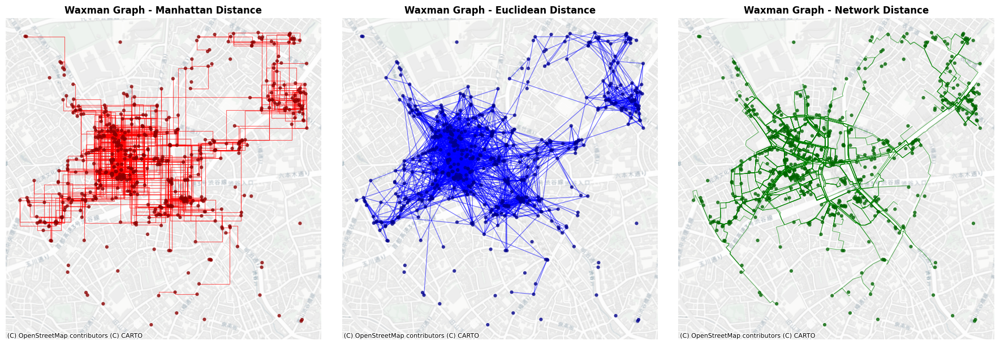

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot Manhattan distance Waxman Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=wax_l1_edges,
    ax=axes[0],
    node_color='darkred',
    edge_color='red',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6,
    bgcolor="white"
    )

ctx.add_basemap(axes[0], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

axes[0].set_title(
    'Waxman Graph - Manhattan Distance',
    fontsize=12,
    fontweight='bold'
    )
axes[0].set_axis_off()

# Plot Euclidean distance Waxman Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=wax_l2_edges,
    ax=axes[1],
    node_color='darkblue',
    edge_color='blue',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6,
    bgcolor="white"
    )

ctx.add_basemap(axes[1], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

axes[1].set_title(
    'Waxman Graph - Euclidean Distance',
    fontsize=12,
    fontweight='bold'
    )
axes[1].set_axis_off()

# Plot Network distance Waxman Graph
c2g.plot_graph(
    nodes=poi_gdf,
    edges=wax_net_edges,
    ax=axes[2],
    node_color='darkgreen',
    edge_color='green',
    markersize=20,
    node_alpha=0.8,
    edge_linewidth=0.8,
    edge_alpha=0.6,
    bgcolor="white"
    )

ctx.add_basemap(axes[2], crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

axes[2].set_title(
    'Waxman Graph - Network Distance',
    fontsize=12,
    fontweight='bold'
    )
axes[2].set_axis_off()

plt.tight_layout()
plt.show()

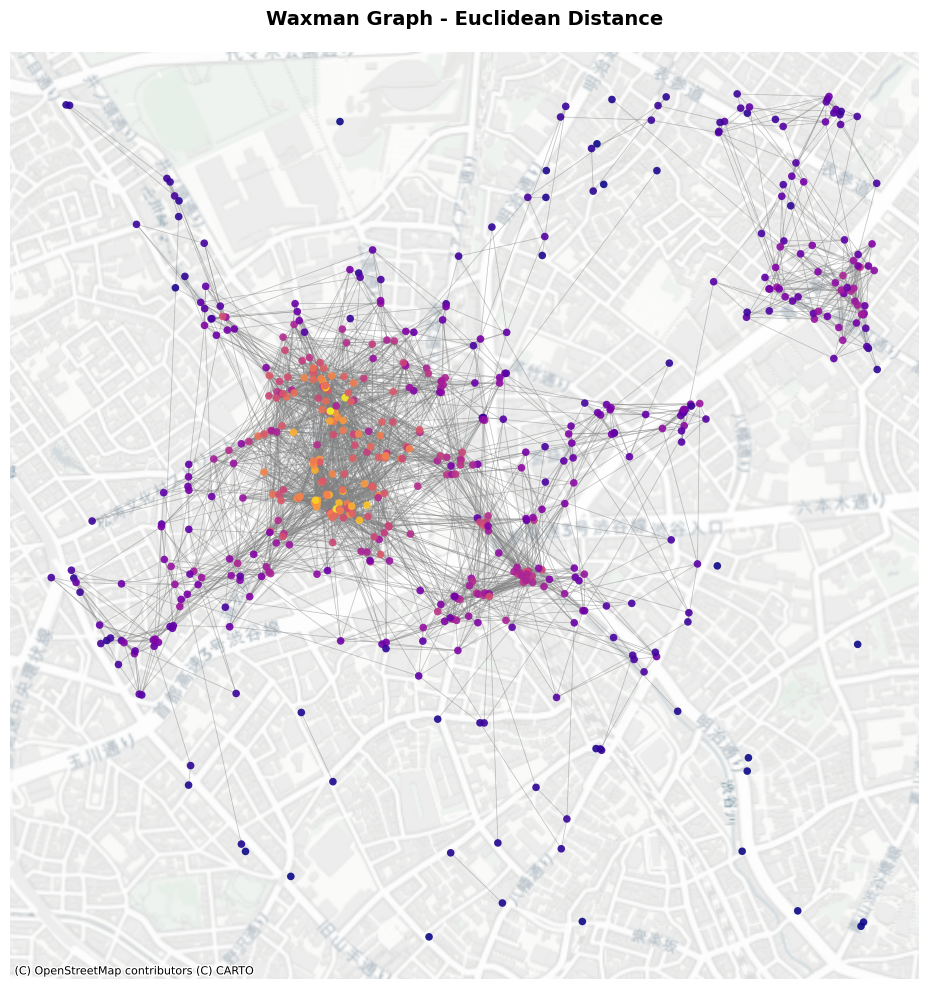

In [18]:
wax_l2_G = c2g.waxman_graph(
    poi_gdf,
    distance_metric="euclidean",
    r0=100,
    beta=0.5,
    as_nx=True
    )
fig, ax = plt.subplots(figsize=(12, 10))

c2g.plot_graph(
    graph=wax_l2_G,
    ax=ax,
    node_color=get_degree_colors(wax_l2_G),
    edge_color="grey",
    edge_alpha=0.5,
    edge_linewidth=0.5,
    node_alpha=0.9,
    markersize=30,
    bgcolor="white"
    )

if poi_gdf.crs:
    ctx.add_basemap(ax, crs=poi_gdf.crs, source=ctx.providers.CartoDB.Positron)

ax.set_title(
    "Waxman Graph - Euclidean Distance",
    fontsize=14,
    fontweight="bold",
    pad=20
    )
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [19]:
HTML("""
<video controls style="width: 100%; max-width: 800px; height: auto;">
    <source src="../assets/videos/waxman_graph.mp4" type="video/mp4">
</video>
""")

## 7. Other Available Proximity Graph Types

city2graph provides further proximity constructions beyond those demonstrated above:

- **Euclidean minimum spanning tree (EMST)**: the sparsest connected graph, exactly $n-1$ edges with minimum total length.
- **Gabriel graph**: two nodes are connected if no other node lies within the circle whose diameter joins them.
- **Relative neighbourhood graph (RNG)**: two nodes are connected if no third node is closer to both of them than they are to each other.

In decreasing edge density: Delaunay ⊃ Gabriel ⊃ RNG ⊃ EMST. The sparser constructions retain only the locally strongest relationships, which makes them useful when a minimal backbone of spatial interaction is wanted.

## 8. Bridge Nodes (Multi-layer Networks)

`bridge_nodes` creates directed proximity edges between different layers of nodes — from every node in one layer to its nearest neighbours in another, by either KNN or fixed radius. This is the building block for multi-layer graphs in which several entity types interact.

Three node types — restaurants, hospitals, and commercial amenities — are extracted from OpenStreetMap for Shibuya, Tokyo.

In [20]:
# Create different layers of POIs for multi-layer analysis
# Let's create hospitals and commercial POIs in addition to restaurants

# Hospitals layer
hospital_tags = {
    "amenity": [
        "hospital"]}

hospital_gdf = ox.features_from_point(
    (35.658514, 139.70133),  # Tokyo Tower coordinates
    tags=hospital_tags,
    dist=1000,  # Search radius in meters
    )

# Filter to include only nodes, not ways and relations
hospital_gdf = hospital_gdf[hospital_gdf.index.get_level_values("element") == "node"]
hospital_gdf = hospital_gdf.to_crs(epsg=6677)

# Commercial layer (shops)
commercial_tags = {
    "shop": True}

commercial_gdf = ox.features_from_point(
    (35.658514, 139.70133),  # Tokyo Tower coordinates
    tags=commercial_tags,
    dist=1000,  # Search radius in meters
    )

# Filter to include only nodes and take a subset to avoid too many points
commercial_gdf = commercial_gdf[commercial_gdf.index.get_level_values("element") == "node"]
commercial_gdf = commercial_gdf.to_crs(epsg=6677)

# Take a subset for better visualization
commercial_gdf = commercial_gdf.sample(min(30, len(commercial_gdf)), random_state=42)

print(f"Restaurants: {len(poi_gdf)} nodes")
print(f"Hospitals: {len(hospital_gdf)} nodes") 
print(f"Commercial: {len(commercial_gdf)} nodes")

Restaurants: 563 nodes
Hospitals: 6 nodes
Commercial: 30 nodes


A dictionary mapping layer names to node GeoDataFrames is passed to `bridge_nodes`, which generates the proximity edges.

In [21]:
# Create a nodes dictionary for multi-layer network
nodes_dict = {
    "restaurants": poi_gdf,
    "hospitals": hospital_gdf,
    "commercial": commercial_gdf
}

# Generate proximity edges between layers using KNN method
proximity_nodes, proximity_edges = c2g.bridge_nodes(
    nodes_dict, 
    proximity_method="knn", 
    k=5,  # Connect to 5 nearest neighbors in each target layer
    distance_metric="euclidean"
)

print("Generated edge types:")
for edge_key in proximity_edges.keys():
    print(
        f"  {edge_key[0]} → {edge_key[2]}: {len(proximity_edges[edge_key])} edges"
        )

Generated edge types:
  restaurants → hospitals: 2815 edges
  restaurants → commercial: 2815 edges
  hospitals → restaurants: 30 edges
  hospitals → commercial: 30 edges
  commercial → restaurants: 150 edges
  commercial → hospitals: 150 edges


The result contains six edge types, one for each ordered pair of layers.

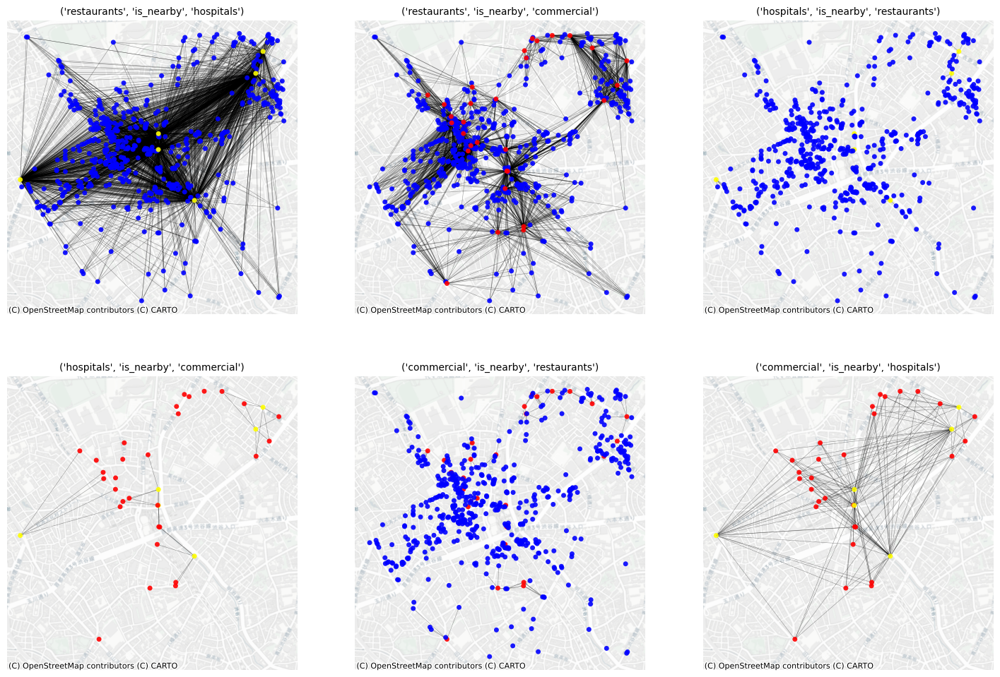

In [22]:
# Prepare for axes in advance
fig, ax = plt.subplots(2, 3, figsize=(18, 12))

# Visualize the multi-layer network connections
c2g.plot_graph(
    nodes=proximity_nodes,
    edges=proximity_edges,
    ax=ax,
    subplots=True,
    node_color={
        "restaurants": "blue",
        "hospitals": "yellow",
        "commercial": "red"
    },
    edge_color="black",
    edge_alpha=0.4,
    edge_linewidth=0.4,
    node_alpha=0.9,
    markersize={"restaurants": 25, "hospitals": 25, "commercial": 25},
    bgcolor="white",
    title_color="black"
)

# Set basemap
for a in ax.flatten():
    ctx.add_basemap(
        a,
        crs=proximity_nodes["restaurants"].crs,
        source=ctx.providers.CartoDB.Positron
        )
    a.set_axis_off()

In [23]:
# Compare with fixed-radius method
radius_nodes, radius_edges = c2g.bridge_nodes(
    nodes_dict,
    proximity_method="fixed_radius",
    radius=500,  # 500 meter radius
    distance_metric="euclidean"
)

print("\nFixed-radius method (500m radius):")
print("Generated edge types:")
total_knn_edges = sum(len(gdf) for gdf in proximity_edges.values())
total_radius_edges = sum(len(gdf) for gdf in radius_edges.values())

for edge_key in proximity_edges.keys():
    knn_count = len(proximity_edges[edge_key])
    radius_count = len(radius_edges[edge_key]) if edge_key in radius_edges else 0
    print(f"  {edge_key[0]} → {edge_key[2]}: KNN(k=2)={knn_count}, Fixed-radius(200m)={radius_count}")

print(f"\nTotal edges: KNN={total_knn_edges}, Fixed-radius={total_radius_edges}")


Fixed-radius method (500m radius):
Generated edge types:
  restaurants → hospitals: KNN(k=2)=2815, Fixed-radius(200m)=958
  restaurants → commercial: KNN(k=2)=2815, Fixed-radius(200m)=4967
  hospitals → restaurants: KNN(k=2)=30, Fixed-radius(200m)=958
  hospitals → commercial: KNN(k=2)=30, Fixed-radius(200m)=46
  commercial → restaurants: KNN(k=2)=150, Fixed-radius(200m)=4967
  commercial → hospitals: KNN(k=2)=150, Fixed-radius(200m)=46

Total edges: KNN=5990, Fixed-radius=11942


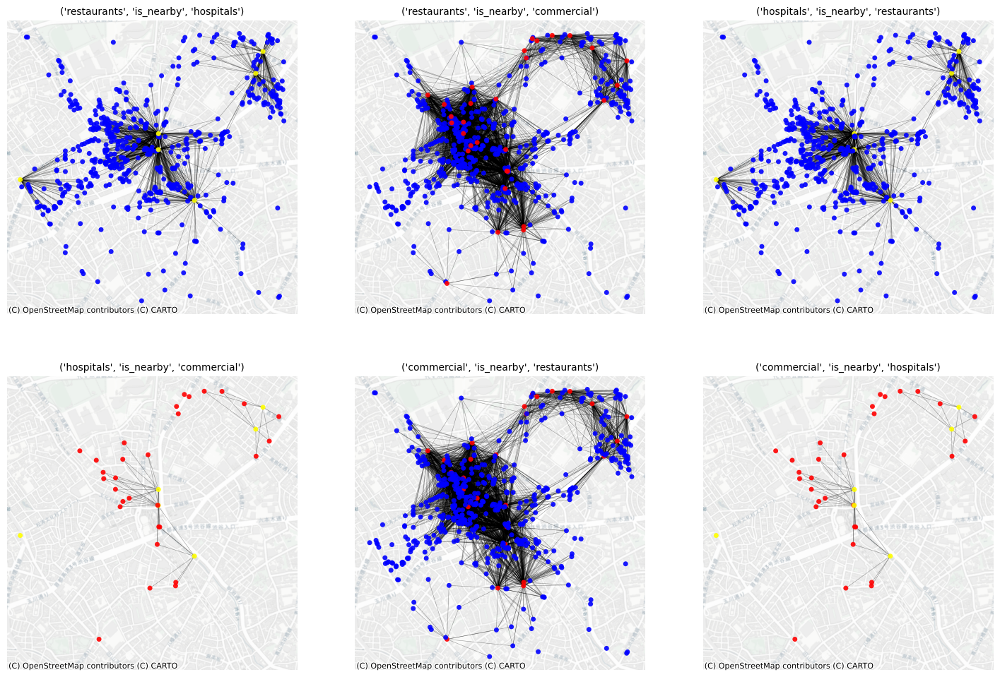

In [24]:
# Prepare for axes in advance
fig, ax = plt.subplots(2, 3, figsize=(18, 12))

# Visualize the multi-layer network connections
c2g.plot_graph(
    nodes=radius_nodes,
    edges=radius_edges,
    ax=ax,
    subplots=True,
    node_color={
        "restaurants": "blue",
        "hospitals": "yellow",
        "commercial": "red"
    },
    edge_color="black",
    edge_alpha=0.4,
    edge_linewidth=0.4,
    node_alpha=0.9,
    markersize={"restaurants": 25, "hospitals": 25, "commercial": 25},
    bgcolor="white",
    title_color="black"
)


# Set basemap
for a in ax.flatten():
    ctx.add_basemap(
        a,
        crs=radius_nodes["restaurants"].crs,
        source=ctx.providers.CartoDB.Positron
        )
    a.set_axis_off()

Layers produced by other city2graph functions can be stacked the same way. The next example bridges a street network with a bus network; see the [transportation API documentation](https://city2graph.net/api/transportation.html) for `load_gtfs` and `travel_summary_graph`.

Here OpenStreetMap streets and a GTFS feed for Greater London provide the two layers.

In [25]:
# Load GTFS data for travel summary graph generation
sample_gtfs_path = "./data/itm_london_gtfs.zip"
gtfs_data = c2g.load_gtfs(sample_gtfs_path)

# Generate travel summary graph for a specific date
travel_summary_nodes, travel_summary_edges = c2g.travel_summary_graph(
    gtfs_data,
    calendar_start="20250601",
    calendar_end="20250601"
    )

# Get the boundary polygon for London from OSMnx
london_boundary = ox.geocode_to_gdf("Greater London, UK").to_crs(epsg=27700)

# Project travel summary data to the same CRS as the bounding box
travel_summary_nodes = travel_summary_nodes.to_crs(epsg=27700)
travel_summary_edges = travel_summary_edges.to_crs(epsg=27700)

# Filter nodes and edges that are within the bounding box
nodes_in_bound = gpd.sjoin(
    travel_summary_nodes,
    london_boundary,
    how="inner"
    ).drop(columns=['index_right'])

edges_in_bound = gpd.sjoin(
    travel_summary_edges,
    london_boundary,
    how="inner"
    ).drop(columns=['index_right'])

# Update the original variables with the filtered data
travel_summary_nodes = nodes_in_bound
travel_summary_edges = edges_in_bound

travel_summary_edges = travel_summary_edges[
    travel_summary_edges.index.get_level_values('from_stop_id').isin(travel_summary_nodes.index) &
    travel_summary_edges.index.get_level_values('to_stop_id').isin(travel_summary_nodes.index)
]

print(f"Nodes within boundary: {len(travel_summary_nodes)}")
print(f"Edges within boundary: {len(travel_summary_edges)}")


Nodes within boundary: 20220
Edges within boundary: 25182


In [26]:
# Download London's street network as a GeoDataFrame
london_graph = ox.graph_from_place("Greater London, UK", network_type="drive")
street_nodes, street_edges = c2g.nx_to_gdf(london_graph)

# Add these lines to project the nodes as well
street_nodes.to_crs(epsg=27700, inplace=True)
travel_summary_nodes.to_crs(epsg=27700, inplace=True)

street_edges.to_crs(epsg=27700, inplace=True)
travel_summary_edges.to_crs(epsg=27700, inplace=True)

`bridge_nodes` is applied to the two node types.

In [27]:
proximity_nodes, proximity_edges = c2g.bridge_nodes(
    {"street": street_nodes,
     "bus": travel_summary_nodes}
    )

The two resulting edge types, `('bus', 'is_nearby', 'street')` and `('street', 'is_nearby', 'bus')`, are shown below.

array([<Axes: title={'center': "('street', 'is_nearby', 'bus')"}>,
       <Axes: title={'center': "('bus', 'is_nearby', 'street')"}>],
      dtype=object)

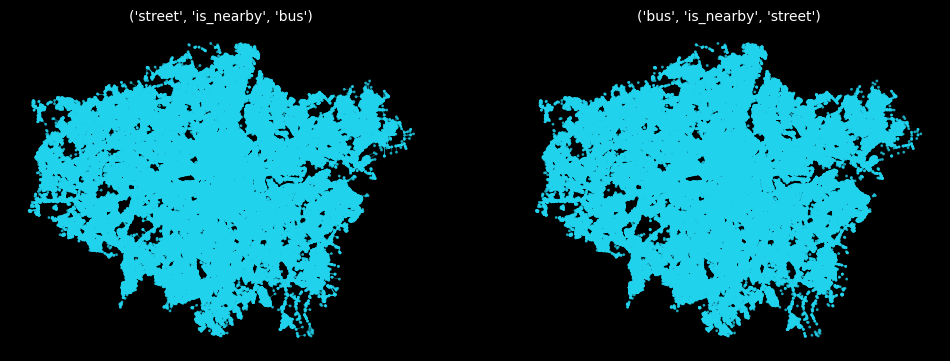

In [28]:
c2g.plot_graph(
    nodes=proximity_nodes,
    edges=proximity_edges,
    ncols=2
)

Alongside the proximity edges, `street_edges` and `travel_summary_edges` are registered as further edge types of the heterogeneous graph. `gdf_to_pyg` then assembles `proximity_nodes` and `proximity_edges` into a `HeteroData` object for PyTorch Geometric.

In [29]:
# Convert proximity_nodes and proximity_edges to HeteroData using gdf_to_pyg
hetero_data = c2g.gdf_to_pyg(proximity_nodes, proximity_edges)

In [30]:
print("HeteroData structure:")
print(hetero_data)
print("\nNode types and their counts:")
for node_type in hetero_data.node_types:
    print(f"  {node_type}: {hetero_data[node_type].x.shape[0]} nodes")
print("\nEdge types and their counts:")
for edge_type in hetero_data.edge_types:
    print(f"  {edge_type}: {hetero_data[edge_type].edge_index.shape[1]} edges")

HeteroData structure:
HeteroData(
  crs=EPSG:27700,
  graph_metadata=<city2graph.base.GraphMetadata object at 0x16b4c6f70>,
  street={
    x=[130474, 0],
    pos=[130474, 2],
  },
  bus={
    x=[20220, 0],
    pos=[20220, 2],
  },
  (street, is_nearby, bus)={
    edge_index=[2, 130474],
    edge_attr=[130474, 0],
  },
  (bus, is_nearby, street)={
    edge_index=[2, 20220],
    edge_attr=[20220, 0],
  }
)

Node types and their counts:
  street: 130474 nodes
  bus: 20220 nodes

Edge types and their counts:
  ('street', 'is_nearby', 'bus'): 130474 edges
  ('bus', 'is_nearby', 'street'): 20220 edges


## 9. Contiguity Graph (Spatial Weights Matrix)

`contiguity_graph` builds spatial networks from polygon geometries: polygons that share boundaries become connected nodes. This is the natural construction for areal units such as administrative boundaries, districts, and land parcels, and it corresponds to the spatial weights matrices used in spatial autocorrelation analysis.

Two contiguity rules are supported:

- **Queen contiguity**: polygons sharing any boundary point (edges or vertices) are connected.
- **Rook contiguity**: only polygons sharing boundary edges are connected.

### Loading Sample Data

The example uses the administrative wards of London. Under the hood, `contiguity_graph` determines neighbours with libpysal's spatial weights.

In [31]:
import geopandas as gpd

# Load London wards shapefile and run contiguity_graph
wards_path = "./data/London-wards-2018/London-wards-2018_ESRI/London_Ward_CityMerged.shp"

# Read
wards = gpd.read_file(wards_path)
print("Wards loaded:", len(wards), ", CRS:", wards.crs)

Wards loaded: 633 , CRS: EPSG:27700


### Generating Queen and Rook Contiguity Graphs

Queen contiguity generally yields more edges than Rook, since polygons touching only at a corner also count as neighbours — the same distinction as the chess pieces' moves.

In [32]:
# Queen contiguity
wn_q_nodes, wn_q_edges = c2g.contiguity_graph(wards, contiguity="queen", as_nx=False)

# Rook contiguity
wn_r_nodes, wn_r_edges = c2g.contiguity_graph(wards, contiguity="rook", as_nx=False)

print(f"Queen — wards: {len(wn_q_nodes)}, edges: {len(wn_q_edges)}")
print(f"Rook  — wards: {len(wn_r_nodes)}, edges: {len(wn_r_edges)}")

Queen — wards: 633, edges: 1865
Rook  — wards: 633, edges: 1797


The output edge table records the contiguity relations.

In [35]:
wn_q_edges

weight                                           geometry
0   6    2293.180212  LINESTRING (517652.344 162339.161, 518064.389 ...
1   3    1477.089130  LINESTRING (519124.935 165300.016, 520118.14 1...
    6    1273.490894  LINESTRING (519124.935 165300.016, 518064.389 ...
    7    1416.550272  LINESTRING (519124.935 165300.016, 518303.176 ...
2   7    1200.560634  LINESTRING (519108.407 167344.325, 518303.176 ...
...              ...                                                ...
626 631  1157.332290  LINESTRING (548034.582 186790.44, 548124.872 1...
627 628  1416.092005  LINESTRING (549443.328 186492.423, 548566.274 ...
    629  1402.322724  LINESTRING (549443.328 186492.423, 550789.867 ...
    631  1571.845404  LINESTRING (549443.328 186492.423, 548124.872 ...
628 630  1897.904259  LINESTRING (548566.274 187604.22, 548359.712 1...

[1865 rows x 2 columns]

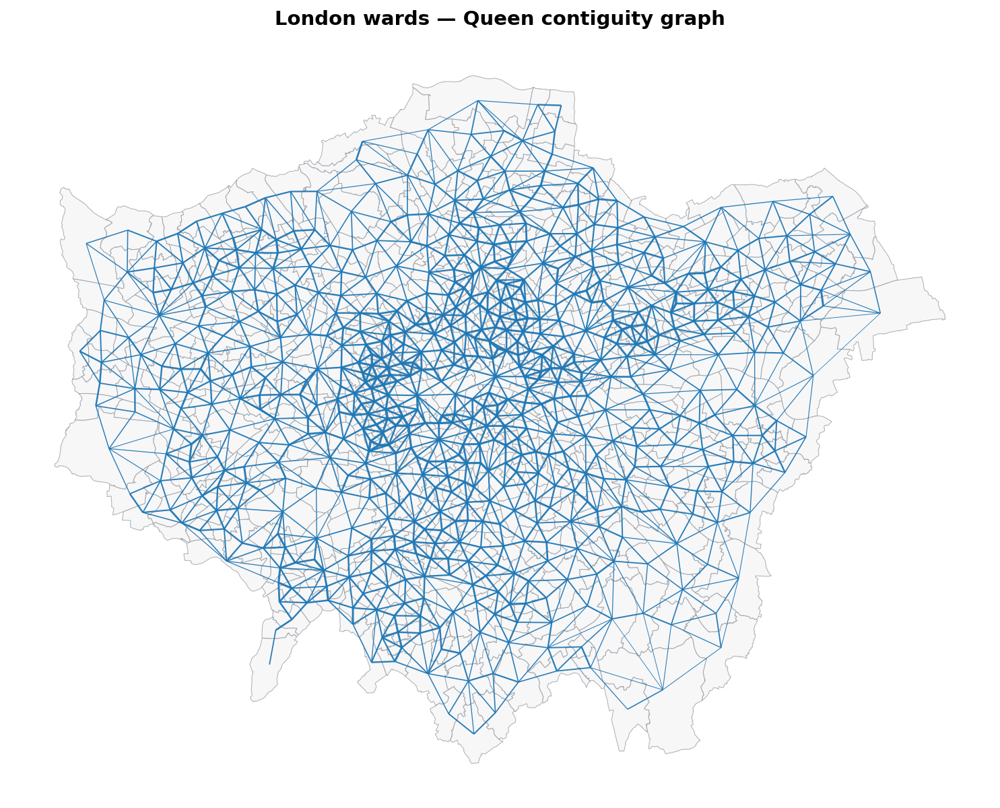

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=150)

w = wn_q_edges["weight"]
# Normalize line widths from edge weights
lw = 0.5 + 2.0 * (w - w.min()) / (w.max() - w.min() if w.max() > w.min() else 1.0)


# Use c2g.plot_graph for consistent plotting
# For contiguity, we treat wards as nodes and the adjacency as edges
c2g.plot_graph(
    nodes=wn_q_nodes,
    edges=wn_q_edges,
    ax=ax,
    bgcolor="white",
    
    # Node styling (Wards polygons)
    node_color="#f5f5f7",   # near-white fill
    node_edgecolor="#9aa0a6", # soft gray outline
    
    # Edge styling (Contiguity links)
    edge_color="#1f77b4",   # vivid blue
    edge_linewidth=1/lw,
    edge_alpha=0.95,
    edge_zorder=3
)

# Focus on content, remove axes clutter
ax.set_axis_off()
ax.set_title("London wards — Queen contiguity graph", fontsize=14, fontweight="bold", pad=12)

plt.tight_layout()
plt.show()

### Computing Network Centrality Measures

Centrality measures on the contiguity graph describe the structural position of each ward:

- **Degree centrality**: how many neighbouring wards a ward has.
- **Betweenness centrality**: how often a ward lies on shortest paths between others, marking bridges between parts of London.
- **Closeness centrality**: how easily a ward is reached from all others.

The measures are computed with NetworkX, and `nx_to_gdf` brings the results back to GeoDataFrames for mapping.

In [41]:
# Basic connectivity using NetworkX
G_wards = c2g.contiguity_graph(wards, contiguity="queen", as_nx=True)

degree_centrality = nx.degree_centrality(G_wards)
nx.set_node_attributes(G_wards, degree_centrality, 'degree_centrality')

betweenness_centrality = nx.betweenness_centrality(G_wards)
nx.set_node_attributes(G_wards, betweenness_centrality, 'betweenness_centrality')

closeness_centrality = nx.closeness_centrality(G_wards)
nx.set_node_attributes(G_wards, closeness_centrality, 'closeness_centrality')

wn_q_nodes, wn_q_edges = c2g.nx_to_gdf(G_wards)

`contiguity_graph` preserves the original polygon attributes, so the computed centralities sit alongside them.

In [42]:
wn_q_nodes.head()

,NAME,GSS_CODE,DISTRICT,LAGSSCODE,HECTARES,NONLD_AREA,geometry,degree_centrality,betweenness_centrality,closeness_centrality
0,Chessington South,E05000405,Kingston upon Thames,E09000021,755.173,0.0,"POLYGON ((516401.596 160201.802, 516407.302 16...",0.001582,0.000000,0.070004
1,Tolworth and Hook Rise,E05000414,Kingston upon Thames,E09000021,259.464,0.0,"POLYGON ((519552.998 164295.6, 519508.096 1643...",0.004747,0.006319,0.081359
2,Berrylands,E05000401,Kingston upon Thames,E09000021,145.390,0.0,"POLYGON ((518107.499 167303.399, 518114.301 16...",0.009494,0.002797,0.088157
3,Alexandra,E05000400,Kingston upon Thames,E09000021,268.506,0.0,"POLYGON ((520336.7 165105.498, 520332.198 1651...",0.009494,0.011225,0.087924
4,Beverley,E05000402,Kingston upon Thames,E09000021,187.821,0.0,"POLYGON ((521201.203 169275.505, 521204.303 16...",0.014241,0.036149,0.095700


The three centralities follow clearly different distributions.

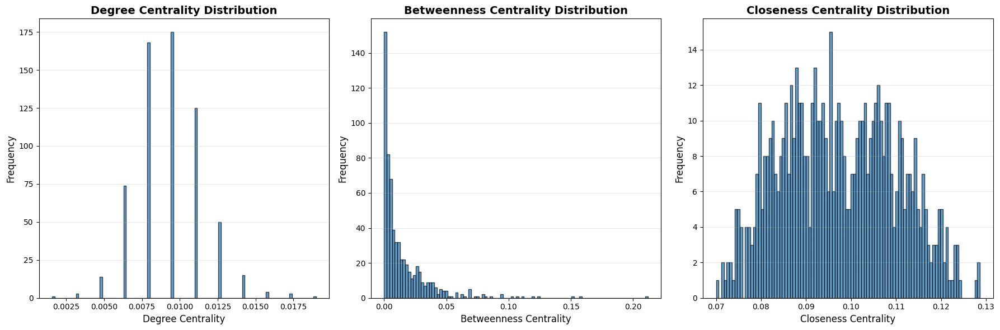

In [43]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Plot Degree Centrality
axes[0].hist(wn_q_nodes['degree_centrality'], bins=100, edgecolor='black', alpha=0.7)
axes[0].set_title('Degree Centrality Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Degree Centrality', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

# Plot Betweenness Centrality
axes[1].hist(wn_q_nodes['betweenness_centrality'], bins=100, edgecolor='black', alpha=0.7)
axes[1].set_title('Betweenness Centrality Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Betweenness Centrality', fontsize=12)
axes[1].set_ylabel('Frequency', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

# Plot Closeness Centrality
axes[2].hist(wn_q_nodes['closeness_centrality'], bins=100, edgecolor='black', alpha=0.7)
axes[2].set_title('Closeness Centrality Distribution', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Closeness Centrality', fontsize=12)
axes[2].set_ylabel('Frequency', fontsize=12)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Mapped as choropleths, the measures vary across London in distinct patterns: degree centrality (left) is highest where wards are small and densely packed, closeness centrality (middle) peaks in central wards nearest to all others, and betweenness centrality (right) picks out the wards that connect different parts of the city.

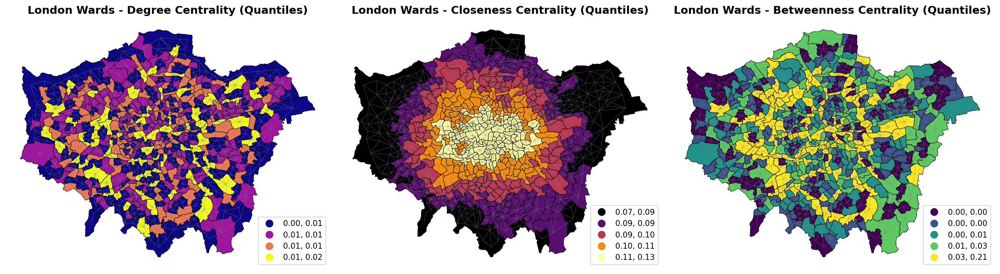

In [44]:
import matplotlib.pyplot as plt

# Plot the wards with centrality measures as choropleth maps using quantile classification
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=150)

# Choropleth map for degree centrality
wn_q_nodes.plot(
    column='degree_centrality',
    ax=axes[0],
    cmap='plasma',
    scheme='quantiles',
    k=5,
    legend=True,
    legend_kwds={'loc': 'lower right'},
    edgecolor='black',
    linewidth=0.5
)
axes[0].set_title('London Wards - Degree Centrality (Quantiles)', fontsize=14, fontweight='bold')
axes[0].set_axis_off()

# Choropleth map for closeness centrality
wn_q_nodes.plot(
    column='closeness_centrality',
    ax=axes[1],
    cmap='inferno',
    scheme='quantiles',
    k=5,
    legend=True,
    legend_kwds={'loc': 'lower right'},
    edgecolor='black',
    linewidth=0.5
)
axes[1].set_title('London Wards - Closeness Centrality (Quantiles)', fontsize=14, fontweight='bold')
axes[1].set_axis_off()

# Choropleth map for betweenness centrality
wn_q_nodes.plot(
    column='betweenness_centrality',
    ax=axes[2],
    cmap='viridis',
    scheme='quantiles',
    k=5,
    legend=True,
    legend_kwds={'loc': 'lower right'},
    edgecolor='black',
    linewidth=0.5
)
axes[2].set_title('London Wards - Betweenness Centrality (Quantiles)', fontsize=14, fontweight='bold')
axes[2].set_axis_off()

# Add contiguity edges to all subplots for context
for ax in axes:
    wn_q_edges.plot(
        ax=ax,
        color='gray',
        linewidth=0.5,
        alpha=0.5
    )

plt.tight_layout()
plt.show()

## 10. Group Nodes

`group_nodes` relates polygon geometries (such as wards) to point geometries (such as bus stations) through a spatial predicate — `"covered_by"` by default, or alternatives such as `"intersects"` and `"within"`. It returns directed edges from each polygon to the points satisfying the predicate, as node and edge dictionaries ready for heterogeneous graph construction, and can record `"euclidean"`, `"manhattan"`, or `"network"` distances on the edges.

### Grouping by Euclidean Distance

The demonstration reuses the ward polygons from the Queen contiguity graph and the bus stations from the travel summary graph, with `distance_metric="euclidean"`.

In [45]:
# Generate proximity edges between wards (polygons) and bus stations (points) using group_nodes
proximity_nodes, proximity_edges = c2g.group_nodes(
    wn_q_nodes,  # polygons_gdf (wards)
    travel_summary_nodes,  # points_gdf (bus stations)
    distance_metric="euclidean", # Distance metric
    predicate="covered_by"  # Default predicate for containment
)

print("Generated edge types:")
for edge_key in proximity_edges.keys():
    print(f"  {edge_key[0]} → {edge_key[2]}: {len(proximity_edges[edge_key])} edges")


Generated edge types:
  polygon → point: 20220 edges


In the visualisation below, each ward is linked to the bus stations it covers.

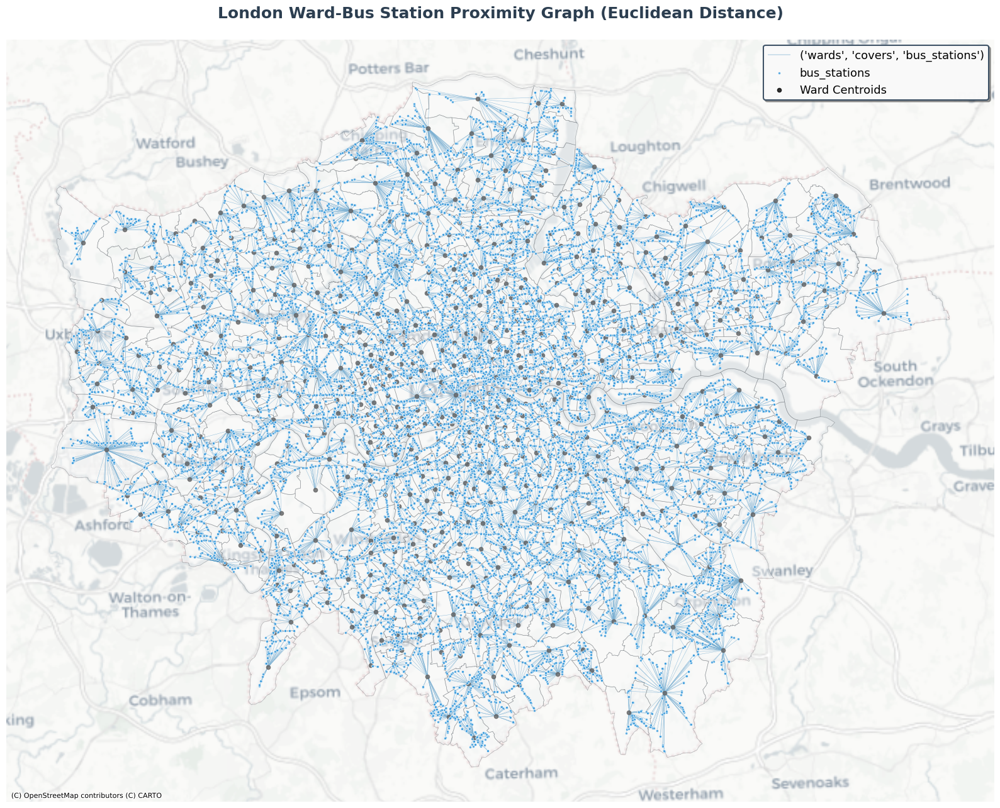

In [46]:
# Plot the proximity graph with enhanced styling and beautiful colors
fig, ax = plt.subplots(1, 1, figsize=(16, 14))

# Create dictionaries for plotting
plot_nodes = {
    'wards': proximity_nodes['polygon'],
    'bus_stations': proximity_nodes['point']
}

plot_edges = {
    ('wards', 'covers', 'bus_stations'): proximity_edges[('polygon', 'covers', 'point')]
}

c2g.plot_graph(
    nodes=plot_nodes,
    edges=plot_edges,
    ax=ax,
    node_color={
        'wards': '#F8F9FA',
        'bus_stations': '#3498DB'
    },
    node_edgecolor={
        'wards': '#495057', 
        'bus_stations': 'white'
    },
    node_alpha={
        'wards': 0.4,
        'bus_stations': 0.8
    },
    markersize={'bus_stations': 8},
    edge_color='#2980B9',
    edge_linewidth=0.3,
    edge_alpha=1,
    bgcolor="white"
)

# Add centroids of polygons with black 'x' markers
centroids = proximity_nodes['polygon'].centroid
ax.scatter(centroids.x, centroids.y, color='black', s=20, alpha=0.8, label='Ward Centroids')

# Add basemap with a clean, modern style
ctx.add_basemap(ax, crs=proximity_nodes['polygon'].crs, source=ctx.providers.CartoDB.Positron)

# Enhanced title and styling
ax.set_title('London Ward-Bus Station Proximity Graph (Euclidean Distance)', 
             fontsize=18, fontweight='bold', pad=25, color='#2C3E50')

# Beautiful legend with custom styling
legend = ax.legend(
    loc='upper right', 
    fontsize=13, 
    framealpha=0.95,
    fancybox=True,
    shadow=True,
    edgecolor='#34495E',
    facecolor='white'
)
legend.get_frame().set_linewidth(1.5)

ax.set_aspect('equal')
ax.axis('off')

# Add subtle border around the plot
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

### Grouping by Network Distance

Network distance works here too, as in the other functions of `proximity.py`; the streets come from OpenStreetMap via OSMnx.

In [ ]:
G_streets = ox.graph_from_place("Greater London, UK", network_type="all")

street_nodes, street_edges = c2g.nx_to_gdf(G_streets)
street_edges.to_crs(epsg=27700, inplace=True)

In [41]:
# Generate proximity edges between wards (polygons) and bus stations (points) using group_nodes
proximity_net_nodes, proximity_net_edges = c2g.group_nodes(
    wn_q_nodes,  # polygons_gdf (wards)
    travel_summary_nodes,  # points_gdf (bus stations)
    distance_metric="network", # Network distance metric
    network_gdf=street_edges,  # Network for distance calculations (not used for containment
    predicate="covered_by"  # Default predicate for containment
)

print("Generated edge types:")
for edge_key in proximity_net_edges.keys():
    print(f"  {edge_key[0]} → {edge_key[2]}: {len(proximity_net_edges[edge_key])} edges")

Generated edge types:
  polygon → point: 20220 edges


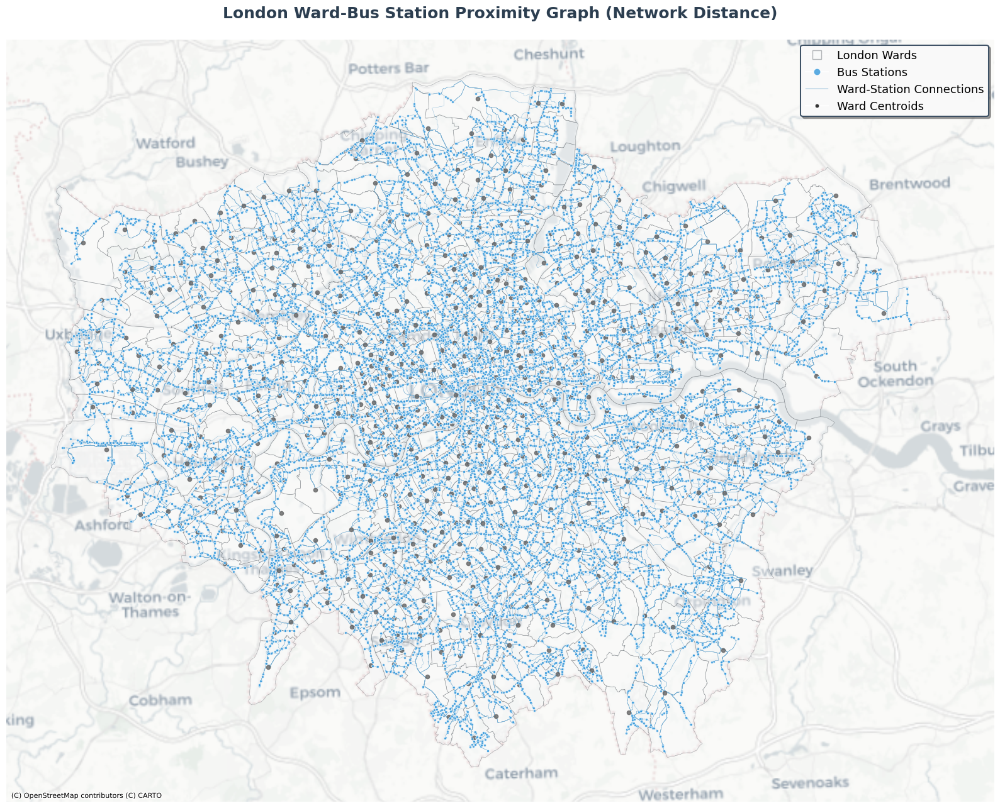

In [42]:
# Plot the proximity graph with enhanced styling and beautiful colors
fig, ax = plt.subplots(1, 1, figsize=(16, 14))

# Use c2g.plot_graph for consistent styling
c2g.plot_graph(
    nodes=proximity_net_nodes,
    edges=proximity_net_edges,
    ax=ax,
    node_color={
        'polygon': '#F8F9FA',
        'point': '#3498DB'
    },
    node_edgecolor={
        'polygon': '#495057',
        'point': 'white'
    },
    node_alpha={
        'polygon': 0.4,
        'point': 0.8
    },
    markersize={'point': 8},
    edge_color='#2980B9',
    edge_linewidth=0.3,
    edge_alpha=1,
    bgcolor="white"
)

# Add centroids of polygons with black 'x' markers
centroids = proximity_net_nodes['polygon'].centroid
ax.scatter(centroids.x, centroids.y, color='black', s=20, alpha=0.8, label='Ward Centroids')

# Add basemap with a clean, modern style
ctx.add_basemap(ax, crs=proximity_net_nodes['polygon'].crs, source=ctx.providers.CartoDB.Positron)

# Enhanced title and styling
ax.set_title('London Ward-Bus Station Proximity Graph (Network Distance)', 
             fontsize=18, fontweight='bold', pad=25, color='#2C3E50')

# Beautiful legend with custom styling
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='s', color='w', label='London Wards',
           markerfacecolor='#F8F9FA', markersize=10, markeredgecolor='#495057', alpha=0.4),
    Line2D([0], [0], marker='o', color='w', label='Bus Stations',
           markerfacecolor='#3498DB', markersize=8, markeredgecolor='white', alpha=0.8),
    Line2D([0], [0], color='#2980B9', lw=0.3, label='Ward-Station Connections'),
    Line2D([0], [0], marker='o', color='w', label='Ward Centroids',
           markerfacecolor='black', markersize=5, alpha=0.8)
]
legend = ax.legend(
    handles=legend_elements,
    loc='upper right', 
    fontsize=13, 
    framealpha=0.95,
    fancybox=True,
    shadow=True,
    edgecolor='#34495E',
    facecolor='white'
)
legend.get_frame().set_linewidth(1.5)

ax.set_aspect('equal')
ax.set_axis_off()

# Add subtle border around the plot
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

The outputs of `group_nodes` feed directly into heterogeneous graph construction: `gdf_to_pyg` (or `nx_to_pyg` for NetworkX objects) assembles the node and edge dictionaries into a PyTorch Geometric `HeteroData`.

In [47]:
# Combine nodes and edges into dictionaries for heterogeneous graph
combined_nodes = {
    'wards': proximity_nodes["polygon"],
    'bus_stations': proximity_nodes["point"]
}

combined_edges = {
    ('wards', 'is_contiguous_with', 'wards'): wn_q_edges,
    ('wards', 'covers', 'bus_stations'): proximity_edges[('polygon', 'covers', 'point')],
    ('bus_stations', 'connects', 'bus_stations'): travel_summary_edges
}

# Create heterogeneous graph using city2graph
wards_bus_hetero_data = c2g.gdf_to_pyg(combined_nodes, combined_edges)

print("Combined Heterogeneous Graph Structure:")
print(wards_bus_hetero_data)
print("\nNode types and their counts:")
for node_type in wards_bus_hetero_data.node_types:
    print(f"  {node_type}: {wards_bus_hetero_data[node_type].x.shape[0]} nodes")
print("\nEdge types and their counts:")
for edge_type in wards_bus_hetero_data.edge_types:
    print(f"  {edge_type}: {wards_bus_hetero_data[edge_type].edge_index.shape[1]} edges")

Combined Heterogeneous Graph Structure:
HeteroData(
  crs=EPSG:27700,
  graph_metadata=<city2graph.base.GraphMetadata object at 0x3dc65bee0>,
  wards={
    x=[633, 0],
    pos=[633, 2],
  },
  bus_stations={
    x=[20220, 0],
    pos=[20220, 2],
  },
  (wards, is_contiguous_with, wards)={
    edge_index=[2, 1865],
    edge_attr=[1865, 0],
  },
  (wards, covers, bus_stations)={
    edge_index=[2, 20220],
    edge_attr=[20220, 0],
  },
  (bus_stations, connects, bus_stations)={
    edge_index=[2, 25182],
    edge_attr=[25182, 0],
  }
)

Node types and their counts:
  wards: 633 nodes
  bus_stations: 20220 nodes

Edge types and their counts:
  ('wards', 'is_contiguous_with', 'wards'): 1865 edges
  ('wards', 'covers', 'bus_stations'): 20220 edges
  ('bus_stations', 'connects', 'bus_stations'): 25182 edges


The combined heterogeneous graph is visualised below.

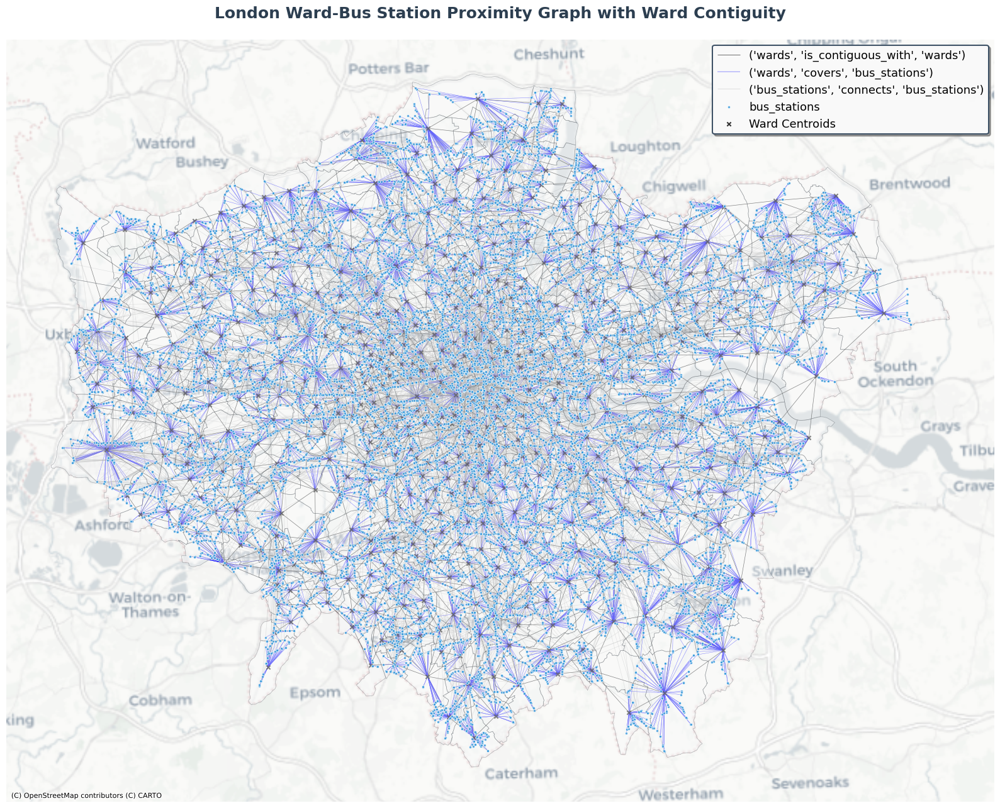

In [58]:
# Plot the combined heterogeneous graph with enhanced styling and beautiful colors
fig, ax = plt.subplots(1, 1, figsize=(16, 14))

# Use built-in plot_graph for heterogeneous graph plotting
c2g.plot_graph(
    nodes=combined_nodes,
    edges=combined_edges,
    ax=ax,
    node_color={
        'wards': '#F8F9FA',
        'bus_stations': '#3498DB'
    },
    node_edgecolor={
        'wards': '#495057',
        'bus_stations': 'white'
    },
    node_alpha={
        'wards': 0.4,
        'bus_stations': 0.8
    },
    markersize={'bus_stations': 8},
    edge_color={
        ('wards', 'is_contiguous_with', 'wards'): 'black',
        ('wards', 'covers', 'bus_stations'): 'blue',
        ('bus_stations', 'connects', 'bus_stations'): 'gray' # Add valid color if needed, or it will use default
    },
    edge_linewidth={
        ('wards', 'is_contiguous_with', 'wards'): 0.5,
        ('wards', 'covers', 'bus_stations'): 0.3
    },
    edge_alpha={
        ('wards', 'is_contiguous_with', 'wards'): 0.8,
        ('wards', 'covers', 'bus_stations'): 1
    },
    bgcolor="white",
    subplots=False
)

# Add centroids of polygons with black 'x' markers
centroids = combined_nodes['wards'].centroid
ax.scatter(centroids.x, centroids.y, color='black', s=20, alpha=0.8, marker='x', label='Ward Centroids')

# Add basemap with a clean, modern style
ctx.add_basemap(ax, crs=combined_nodes['wards'].crs, source=ctx.providers.CartoDB.Positron)

# Enhanced title and styling
ax.set_title('London Ward-Bus Station Proximity Graph with Ward Contiguity', 
             fontsize=18, fontweight='bold', pad=25, color='#2C3E50')

# Beautiful legend with custom styling
legend = ax.legend(
    loc='upper right', 
    fontsize=13, 
    framealpha=0.95,
    fancybox=True,
    shadow=True,
    edgecolor='#34495E',
    facecolor='white'
)
legend.get_frame().set_linewidth(1.5)

ax.set_aspect('equal')
ax.axis('off')

# Add subtle border around the plot
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()